## Load Dataset

In [1]:
import os, shutil, pathlib

# Root working dir inside Colab
PROJ_ROOT = "/content/hand_bbox_baseline"
DATA_ROOT = f"{PROJ_ROOT}/data"
RAW_ROOT  = f"{DATA_ROOT}/raw"          # where the original Kaggle files live (read-only for us)
WORK_ROOT = f"{DATA_ROOT}/work"         # where we'll convert/normalize annotations
os.makedirs(RAW_ROOT, exist_ok=True)
os.makedirs(WORK_ROOT, exist_ok=True)

for p in [PROJ_ROOT, DATA_ROOT, RAW_ROOT, WORK_ROOT]:
    print(p, "OK" if os.path.exists(p) else "MISSING")


/content/hand_bbox_baseline OK
/content/hand_bbox_baseline/data OK
/content/hand_bbox_baseline/data/raw OK
/content/hand_bbox_baseline/data/work OK


In [2]:
!pip -q install kagglehub scipy matplotlib pillow

import kagglehub, os, shutil, glob

# 1) Download to KaggleHub cache; returns a directory
cache_path = kagglehub.dataset_download("armannikkhah/hand-dataset")
print("KaggleHub cache:", cache_path)

# 2) Copy everything from cache to our RAW_ROOT, but don't duplicate if already copied
def copytree(src, dst):
    src = os.path.abspath(src)
    dst = os.path.abspath(dst)
    for root, dirs, files in os.walk(src):
        rel = os.path.relpath(root, src)
        dest_dir = os.path.join(dst, rel) if rel != "." else dst
        os.makedirs(dest_dir, exist_ok=True)
        for f in files:
            src_f = os.path.join(root, f)
            dst_f = os.path.join(dest_dir, f)
            if not os.path.exists(dst_f):
                shutil.copy2(src_f, dst_f)

copytree(cache_path, RAW_ROOT)

# 3) Quick peek: list a few items
for path in glob.glob(os.path.join(RAW_ROOT, "*"))[:20]:
    print(path)


100%|██████████| 243M/243M [00:03<00:00, 79.3MB/s]

Extracting files...


KaggleHub cache: /root/.cache/kagglehub/datasets/armannikkhah/hand-dataset/versions/1
/content/hand_bbox_baseline/data/raw/hand_dataset


In [3]:
import os, glob, json, re
from collections import Counter

root = RAW_ROOT
all_files = [os.path.relpath(p, root) for p in glob.glob(os.path.join(root, "**"), recursive=True) if os.path.isfile(p)]
exts = Counter([os.path.splitext(f)[1].lower() for f in all_files])

print("Top-level files:")
for f in sorted([p for p in all_files if os.sep not in p])[:50]:
    print("  ", f)

print("\nExtensions frequency:", dict(exts))

# Check for common annotation containers
candidates = []
for pat in ["*.xml", "*.json", "*.csv", "*.txt"]:
    matches = glob.glob(os.path.join(root, "**", pat), recursive=True)
    if matches:
        candidates.append((pat, len(matches), matches[:5]))
print("\nPotential annotation files:")
for pat, n, sample in candidates:
    print(f"  {pat}: {n} files (sample: {[os.path.relpath(s, root) for s in sample]})")


Top-level files:

Extensions frequency: {'.m': 27, '.txt': 9, '.jpg': 6064, '.mat': 5630, '': 4, '.xml': 436}

Potential annotation files:
  *.xml: 436 files (sample: ['hand_dataset/evaluation_code/VOC2007/VOCdevkit/VOC2007/Annotations/010008_hand.xml', 'hand_dataset/evaluation_code/VOC2007/VOCdevkit/VOC2007/Annotations/010253_hand.xml', 'hand_dataset/evaluation_code/VOC2007/VOCdevkit/VOC2007/Annotations/010034_hand.xml', 'hand_dataset/evaluation_code/VOC2007/VOCdevkit/VOC2007/Annotations/010156_hand.xml', 'hand_dataset/evaluation_code/VOC2007/VOCdevkit/VOC2007/Annotations/010364_hand.xml'])
  *.txt: 9 files (sample: ['hand_dataset/README.txt', 'hand_dataset/validation_dataset/README.txt', 'hand_dataset/evaluation_code/README.txt', 'hand_dataset/evaluation_code/VOC2007/VOCdevkit/results/VOC2007/Main/comp3_det_val_hand.txt', 'hand_dataset/evaluation_code/VOC2007/VOCdevkit/results/VOC2007/Main/comp3_det_val_person.txt'])


In [4]:
import glob, os, xml.etree.ElementTree as ET

# Try to find the VOC root that contains Annotations and JPEGImages
VOC_ROOT = None
for root, dirs, files in os.walk(RAW_ROOT):
    if "Annotations" in dirs and "JPEGImages" in dirs:
        VOC_ROOT = os.path.join(root)
        break

print("VOC_ROOT:", VOC_ROOT)

# List a few example files
print("\nSome annotation files:")
for path in glob.glob(os.path.join(VOC_ROOT, "Annotations", "*.xml"))[:5]:
    print(" ", os.path.basename(path))

print("\nSome images:")
for path in glob.glob(os.path.join(VOC_ROOT, "JPEGImages", "*.jpg"))[:5]:
    print(" ", os.path.basename(path))


VOC_ROOT: /content/hand_bbox_baseline/data/raw/hand_dataset/evaluation_code/VOC2007/VOCdevkit/VOC2007

Some annotation files:
  010008_hand.xml
  010253_hand.xml
  010034_hand.xml
  010156_hand.xml
  010364_hand.xml

Some images:
  010128_hand.jpg
  010060_hand.jpg
  010024_hand.jpg
  010240_hand.jpg
  010232_hand.jpg


In [5]:
import os, xml.etree.ElementTree as ET
from pprint import pprint

sample_xml = os.path.join(VOC_ROOT, "Annotations", "010151_hand.xml")  # pick any name from the list you saw
tree = ET.parse(sample_xml)
root = tree.getroot()

# Pull a few top-level fields
img_filename = root.findtext("filename")
size_w = int(root.find("size/width").text)
size_h = int(root.find("size/height").text)

print("Image file:", img_filename)
print("Image size:", size_w, "x", size_h)

# Objects = annotated instances (hands)
objects = []
for obj in root.findall("object"):
    name = obj.findtext("name")
    bbox = obj.find("bndbox")
    xmin = int(float(bbox.findtext("xmin")))
    ymin = int(float(bbox.findtext("ymin")))
    xmax = int(float(bbox.findtext("xmax")))
    ymax = int(float(bbox.findtext("ymax")))
    # VOC is 1-based in some old tools; these files typically store 1-based ints.
    # We'll convert to 0-based later if needed; for now just inspect.
    objects.append({"name": name, "xmin": xmin, "ymin": ymin, "xmax": xmax, "ymax": ymax})

print("\nFound objects:")
pprint(objects)

Image file: 010151_hand.jpg
Image size: 375 x 500

Found objects:
[{'name': 'hand', 'xmax': 178, 'xmin': 14, 'ymax': 496, 'ymin': 336},
 {'name': 'hand', 'xmax': 107, 'xmin': 21, 'ymax': 282, 'ymin': 173}]


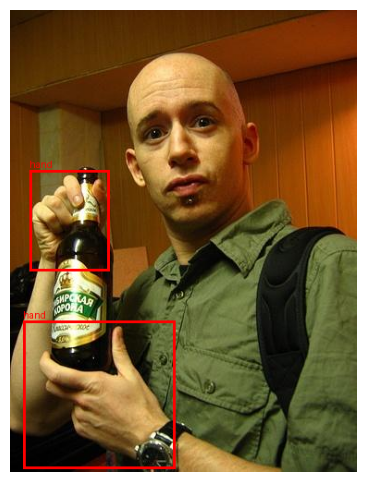

In [6]:
import os
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

jpg_path = os.path.join(VOC_ROOT, "JPEGImages", img_filename)
im = Image.open(jpg_path).convert("RGB")
draw = ImageDraw.Draw(im)

for o in objects:
    # VOC boxes are inclusive; PIL rectangle is fine with these corners.
    draw.rectangle([(o["xmin"], o["ymin"]), (o["xmax"], o["ymax"])], outline=(255,0,0), width=3)
    draw.text((o["xmin"], max(0, o["ymin"]-12)), o["name"], fill=(255,0,0))

plt.figure(figsize=(6,6))
plt.imshow(im)
plt.axis("off")
plt.show()


In [7]:
import glob, csv

ann_dir = os.path.join(VOC_ROOT, "Annotations")
img_dir = os.path.join(VOC_ROOT, "JPEGImages")

rows = []
xml_files = sorted(glob.glob(os.path.join(ann_dir, "*.xml")))
print("XML files:", len(xml_files))

for xml_path in xml_files:
    root = ET.parse(xml_path).getroot()
    filename = root.findtext("filename")
    W = int(root.find("size/width").text)
    H = int(root.find("size/height").text)
    img_path = os.path.join(img_dir, filename)

    for obj in root.findall("object"):
        name = obj.findtext("name")
        bbox = obj.find("bndbox")
        xmin = int(float(bbox.findtext("xmin")))
        ymin = int(float(bbox.findtext("ymin")))
        xmax = int(float(bbox.findtext("xmax")))
        ymax = int(float(bbox.findtext("ymax")))

        # Clamp to image and ensure xmin<xmax, ymin<ymax
        xmin = max(0, min(xmin, W-1))
        xmax = max(0, min(xmax, W-1))
        ymin = max(0, min(ymin, H-1))
        ymax = max(0, min(ymax, H-1))
        if xmax <= xmin or ymax <= ymin:
            continue  # skip degenerate boxes

        rows.append([img_path, W, H, name, xmin, ymin, xmax, ymax])

print("Total hand instances:", len(rows))

# Save the per-instance CSV in WORK_ROOT
all_boxes_csv = os.path.join(WORK_ROOT, "hand_voc_instances.csv")
with open(all_boxes_csv, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["image_path","width","height","class","xmin","ymin","xmax","ymax"])
    w.writerows(rows)

print("Wrote:", all_boxes_csv)


XML files: 436
Total hand instances: 660
Wrote: /content/hand_bbox_baseline/data/work/hand_voc_instances.csv


In [8]:
import pandas as pd

all_df = pd.read_csv(all_boxes_csv)
print("Instances:", len(all_df), " Unique images:", all_df["image_path"].nunique())

# Compute area and pick the largest box per image
all_df["area"] = (all_df["xmax"] - all_df["xmin"]) * (all_df["ymax"] - all_df["ymin"])
dominant = (all_df.sort_values("area", ascending=False)
                 .groupby("image_path", as_index=False)
                 .first()
                 .drop(columns=["area"]))

baseline_csv = os.path.join(WORK_ROOT, "hand_baseline_dominant_box.csv")
dominant.to_csv(baseline_csv, index=False)
print("Wrote:", baseline_csv, "with", len(dominant), "images")
dominant.head()


Instances: 660  Unique images: 436
Wrote: /content/hand_bbox_baseline/data/work/hand_baseline_dominant_box.csv with 436 images


,image_path,width,height,class,xmin,ymin,xmax,ymax
0,/content/hand_bbox_baseline/data/raw/hand_data...,375,500,hand,63,302,138,369
1,/content/hand_bbox_baseline/data/raw/hand_data...,500,375,hand,183,219,305,356
2,/content/hand_bbox_baseline/data/raw/hand_data...,500,333,hand,153,117,209,174
3,/content/hand_bbox_baseline/data/raw/hand_data...,320,448,hand,242,264,294,325
4,/content/hand_bbox_baseline/data/raw/hand_data...,320,480,hand,160,205,226,270


In [9]:
import pandas as pd, numpy as np, os
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from math import ceil

baseline_csv = "/content/hand_bbox_baseline/data/work/hand_baseline_dominant_box.csv"
df = pd.read_csv(baseline_csv)

# sample a few
np.random.seed(42)
sample = df.sample(12).reset_index(drop=True)

# draw
cols = 4
rows = ceil(len(sample)/cols)
plt.figure(figsize=(cols*4, rows*4))

for i, row in sample.iterrows():
    img = Image.open(row["image_path"]).convert("RGB")
    draw = ImageDraw.Draw(img)
    draw.rectangle([(row["xmin"], row["ymin"]), (row["xmax"], row["ymax"])], outline=(255,0,0), width=3)
    plt.subplot(rows, cols, i+1)
    plt.imshow(img)
    plt.title(os.path.basename(row["image_path"]))
    plt.axis("off")

plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

## Own CNN Model using Keras Model

In [ ]:
import pandas as pd, numpy as np, os

work = "/content/hand_bbox_baseline/data/work"
df = pd.read_csv(os.path.join(work, "hand_baseline_dominant_box.csv"))

# Normalize here to keep the tf.data mapper simpler
df["tx"] = df["xmin"] / df["width"]
df["ty"] = df["ymin"] / df["height"]
df["bx"] = df["xmax"] / df["width"]
df["by"] = df["ymax"] / df["height"]

# Basic sanity: keep within [0,1]
for c in ["tx","ty","bx","by"]:
    df[c] = df[c].clip(0, 1)

# Split (stratification isn’t needed: single class)
np.random.seed(123)
perm = np.random.permutation(len(df))
val_ratio = 0.15
val_n = int(len(df)*val_ratio)
val_idx = set(perm[:val_n])

df["split"] = ["val" if i in val_idx else "train" for i in range(len(df))]
train_df = df[df["split"]=="train"].copy()
val_df   = df[df["split"]=="val"].copy()

train_csv = os.path.join(work, "train_baseline.csv")
val_csv   = os.path.join(work, "val_baseline.csv")
train_df.to_csv(train_csv, index=False)
val_df.to_csv(val_csv, index=False)

print("Train:", len(train_df), " Val:", len(val_df))
print("Saved:\n ", train_csv, "\n ", val_csv)
train_df.head(2), val_df.head(2)


Train: 371  Val: 65
Saved:
  /content/hand_bbox_baseline/data/work/train_baseline.csv 
  /content/hand_bbox_baseline/data/work/val_baseline.csv


(                                          image_path  width  height class  \
 0  /content/hand_bbox_baseline/data/raw/hand_data...    375     500  hand   
 1  /content/hand_bbox_baseline/data/raw/hand_data...    500     375  hand   
 
    xmin  ymin  xmax  ymax     tx     ty     bx        by  split  
 0    63   302   138   369  0.168  0.604  0.368  0.738000  train  
 1   183   219   305   356  0.366  0.584  0.610  0.949333  train  ,
                                           image_path  width  height class  \
 5  /content/hand_bbox_baseline/data/raw/hand_data...    345     500  hand   
 9  /content/hand_bbox_baseline/data/raw/hand_data...    500     375  hand   
 
    xmin  ymin  xmax  ymax        tx     ty        bx     by split  
 5   169   262   232   334  0.489855  0.524  0.672464  0.668   val  
 9   181   252   317   345  0.362000  0.672  0.634000  0.920   val  )

In [ ]:
import tensorflow as tf
import pandas as pd

IMG_SIZE = 224
BATCH = 16
AUTOTUNE = tf.data.AUTOTUNE

work = "/content/hand_bbox_baseline/data/work"
train_csv = f"{work}/train_baseline.csv"
val_csv   = f"{work}/val_baseline.csv"

train_df = pd.read_csv(train_csv)
val_df   = pd.read_csv(val_csv)

def make_ds(df, shuffle=True, repeat=False):
    paths = df["image_path"].values
    labels = df[["tx","ty","bx","by"]].values.astype("float32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def _load(path, y):
        img = tf.io.read_file(path)
        img = tf.io.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        img = tf.cast(img, tf.float32) / 255.0
        return img, y

    ds = ds.map(_load, num_parallel_calls=AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(1024)
    if repeat:
        ds = ds.repeat()
    ds = ds.batch(BATCH).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_df, shuffle=True,  repeat=True)   # infinite for training
val_ds   = make_ds(val_df,   shuffle=False, repeat=False)  # one pass for validation

# Peek one batch to confirm shapes
imgs, ys = next(iter(train_ds))
print("Batch images:", imgs.shape, " Batch labels:", ys.shape, " (expect [B,224,224,3] and [B,4])")


Batch images: (16, 224, 224, 3)  Batch labels: (16, 4)  (expect [B,224,224,3] and [B,4])


Step 7 — Define the model + IoU metric (TensorFlow/Keras)

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = 224

def iou_metric(y_true, y_pred):
    # y_*: [B,4] with normalized [tx,ty,bx,by]
    # ensure valid ordering and clip to [0,1]
    y_true = tf.clip_by_value(y_true, 0.0, 1.0)
    y_pred = tf.clip_by_value(y_pred, 0.0, 1.0)

    # (tx,ty) is top-left; (bx,by) is bottom-right
    xA = tf.maximum(y_true[:,0], y_pred[:,0])
    yA = tf.maximum(y_true[:,1], y_pred[:,1])
    xB = tf.minimum(y_true[:,2], y_pred[:,2])
    yB = tf.minimum(y_true[:,3], y_pred[:,3])

    interW = tf.maximum(0.0, xB - xA)
    interH = tf.maximum(0.0, yB - yA)
    inter  = interW * interH

    area_true = tf.maximum(0.0, (y_true[:,2]-y_true[:,0])) * tf.maximum(0.0, (y_true[:,3]-y_true[:,1]))
    area_pred = tf.maximum(0.0, (y_pred[:,2]-y_pred[:,0])) * tf.maximum(0.0, (y_pred[:,3]-y_pred[:,1]))
    union = area_true + area_pred - inter + 1e-7

    iou = inter / union
    return tf.reduce_mean(iou)

def make_baseline_model():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = inputs

    def block(x, f, s=1):
        x = layers.Conv2D(f, 3, strides=s, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        return x

    x = block(x, 32, s=2)   # 112x112
    x = block(x, 32)
    x = block(x, 64, s=2)   # 56x56
    x = block(x, 64)
    x = block(x, 128, s=2)  # 28x28
    x = block(x, 128)
    x = block(x, 256, s=2)  # 14x14
    x = block(x, 256)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.25)(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(4, activation="linear")(x)  # normalized coords, no sigmoid (let loss handle it)

    model = keras.Model(inputs, outputs, name="hand_bbox_baseline_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.Huber(delta=1.0),
        metrics=[iou_metric]
    )
    return model

baseline_model = make_baseline_model()
baseline_model.summary()


Model: "hand_bbox_baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 56, 56, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,208,548 (4.61 MB)

 Trainable params: 1,206,628 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

Step 8 — Train a few epochs

In [ ]:
import math

EPOCHS = 15
STEPS_PER_EPOCH = math.ceil(371 / 16)  # train size / batch
VAL_STEPS = math.ceil(65 / 16)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_iou_metric", patience=5, mode="max", restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_iou_metric", mode="max", factor=0.5, patience=2, min_lr=1e-5, verbose=1)
]

history = baseline_model.fit(
    train_ds,
    epochs=EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_ds,
    validation_steps=VAL_STEPS,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - iou_metric: 0.0402 - loss: 0.0268 - val_iou_metric: 0.0396 - val_loss: 0.0250 - learning_rate: 2.5000e-04
Epoch 2/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - iou_metric: 0.0410 - loss: 0.0272 - val_iou_metric: 0.0436 - val_loss: 0.0244 - learning_rate: 2.5000e-04
Epoch 3/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - iou_metric: 0.0417 - loss: 0.0280 - val_iou_metric: 0.0437 - val_loss: 0.0250 - learning_rate: 2.5000e-04
Epoch 4/15
23/24 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - iou_metric: 0.0361 - loss: 0.0287
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - iou_metric: 0.0363 - loss: 0.0287 - val_iou_metric: 0.0415 - val_loss: 0.0249 - learning_rate: 2.5000e-04
Epoch 5/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - iou_metric: 0.0362 - loss: 0.0257 - val_iou_metric: 0.0431 - val_loss: 0.0246 - learning_rate: 1.2500e-04
Epoch 6/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - 

Step 9 — Qualitative check: visualize predictions on validation images

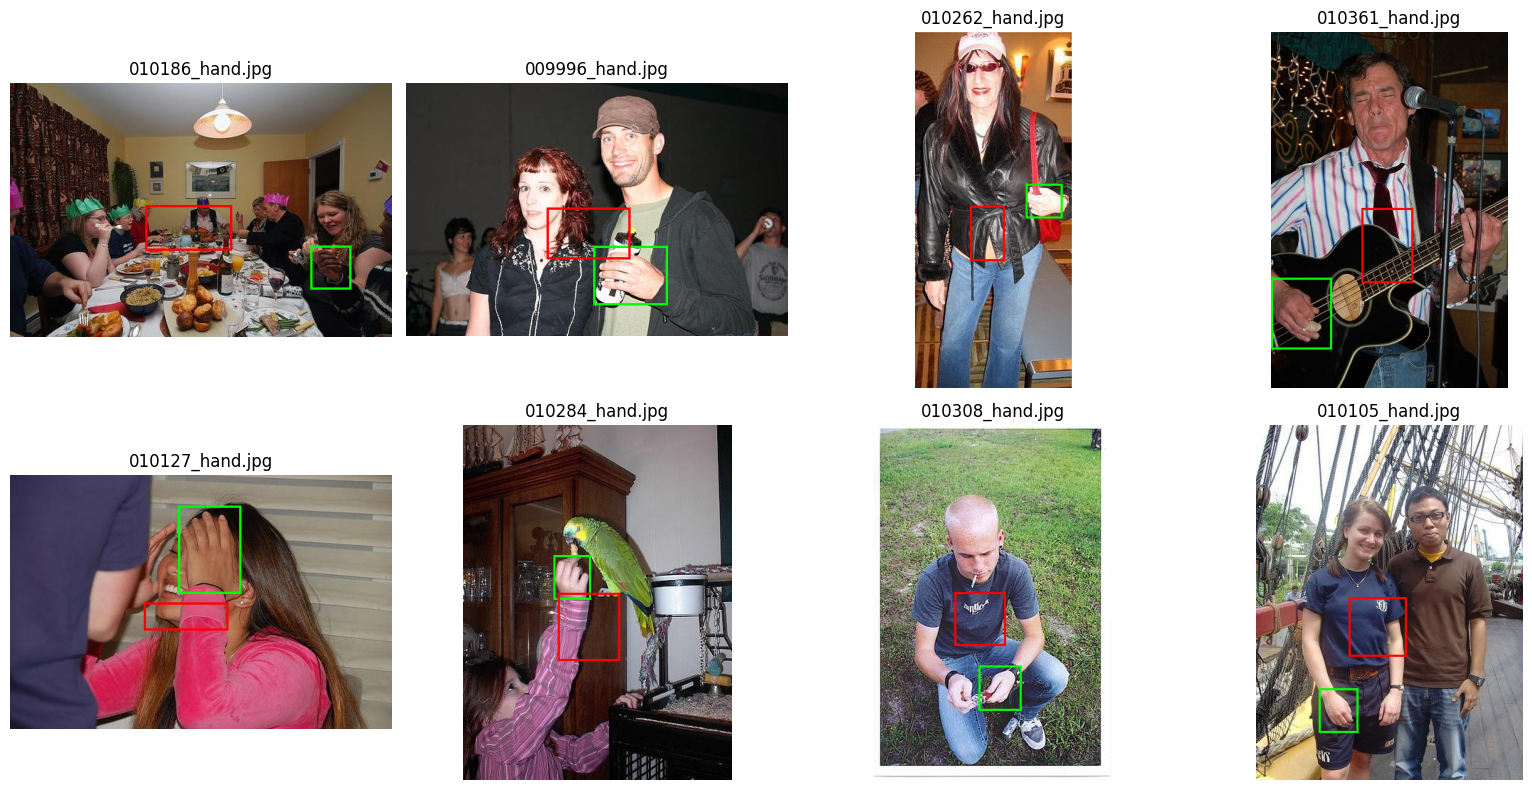

In [ ]:
import pandas as pd, numpy as np, os
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

work = "/content/hand_bbox_baseline/data/work"
val_df = pd.read_csv(f"{work}/val_baseline.csv")

def preprocess_for_model(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img

# sample a few validation images
np.random.seed(7)
vis = val_df.sample(8).reset_index(drop=True)

# Build input batch
batch_imgs = tf.stack([preprocess_for_model(p) for p in vis["image_path"].values], axis=0)
preds = baseline_model.predict(batch_imgs, verbose=0)  # [N,4] normalized

# Plot
cols = 4
rows = int(np.ceil(len(vis)/cols))
plt.figure(figsize=(cols*4, rows*4))

for i, row in vis.iterrows():
    img = Image.open(row["image_path"]).convert("RGB")
    W, H = row["width"], row["height"]

    # GT denorm
    gt = (
        row["tx"]*W, row["ty"]*H,
        row["bx"]*W, row["by"]*H
    )

    # Pred denorm
    pr = preds[i]
    pr = np.clip(pr, 0, 1)
    pr = (pr[0]*W, pr[1]*H, pr[2]*W, pr[3]*H)

    draw = ImageDraw.Draw(img)
    # GT = green, Pred = red
    draw.rectangle([(gt[0], gt[1]), (gt[2], gt[3])], outline=(0,255,0), width=3)
    draw.rectangle([(pr[0], pr[1]), (pr[2], pr[3])], outline=(255,0,0), width=3)

    plt.subplot(rows, cols, i+1)
    plt.imshow(img)
    plt.title(os.path.basename(row["image_path"]))
    plt.axis("off")

plt.tight_layout()
plt.show()


The model I created above is not bad, but is a better aproach to use a pretrained model and finetune it for our purpose in our case wer are going to use the MobileNetv2

## Fine Tunning MobileNetV2

Step 10 — Build a MobileNetV2 regressor (frozen backbone)

In [10]:
import pandas as pd, os, numpy as np

work = "/content/hand_bbox_baseline/data/work"
all_csv = f"{work}/hand_voc_instances.csv"         # per-instance CSV we created earlier

df_all = pd.read_csv(all_csv)
counts = df_all.groupby("image_path").size().rename("num_hands")
onehand = (counts == 1)
print("Images total:", counts.shape[0], " | single-hand images:", onehand.sum())

# keep only those images
df1 = (df_all.merge(counts, left_on="image_path", right_index=True)
              .query("num_hands == 1")
              .drop(columns=["num_hands"])
              .copy())

# rename to the baseline format and compute normalized coords
df1["tx"] = df1["xmin"] / df1["width"]
df1["ty"] = df1["ymin"] / df1["height"]
df1["bx"] = df1["xmax"] / df1["width"]
df1["by"] = df1["ymax"] / df1["height"]
for c in ["tx","ty","bx","by"]:
    df1[c] = df1[c].clip(0,1)

# split
np.random.seed(123)
idx = np.random.permutation(len(df1))
val_n = max(1, int(0.15*len(df1)))
val_idx = set(idx[:val_n])
df1["split"] = ["val" if i in val_idx else "train" for i in range(len(df1))]

train1 = df1[df1["split"]=="train"].copy()
val1   = df1[df1["split"]=="val"].copy()

train_csv_1 = f"{work}/train_singlehand.csv"
val_csv_1   = f"{work}/val_singlehand.csv"
train1.to_csv(train_csv_1, index=False)
val1.to_csv(val_csv_1, index=False)

print("Train single-hand:", len(train1), " Val:", len(val1))


Images total: 436  | single-hand images: 254
Train single-hand: 216  Val: 38


In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def to_corners(params):
    # params: [B,4] = cx, cy, w, h (all normalized)
    cx, cy, w, h = tf.split(params, 4, axis=-1)
    # clip so widths/heights don’t exceed image (1.0)
    w = tf.clip_by_value(w, 1e-6, 1.0)
    h = tf.clip_by_value(h, 1e-6, 1.0)
    tx = tf.clip_by_value(cx - w/2.0, 0.0, 1.0)
    ty = tf.clip_by_value(cy - h/2.0, 0.0, 1.0)
    bx = tf.clip_by_value(cx + w/2.0, 0.0, 1.0)
    by = tf.clip_by_value(cy + h/2.0, 0.0, 1.0)
    return tf.concat([tx,ty,bx,by], axis=-1)

def iou_metric(y_true, y_pred):
    y_true = tf.clip_by_value(y_true, 0.0, 1.0)
    y_pred = tf.clip_by_value(y_pred, 0.0, 1.0)
    xA = tf.maximum(y_true[:,0], y_pred[:,0]); yA = tf.maximum(y_true[:,1], y_pred[:,1])
    xB = tf.minimum(y_true[:,2], y_pred[:,2]); yB = tf.minimum(y_true[:,3], y_pred[:,3])
    inter = tf.maximum(0.0, xB-xA) * tf.maximum(0.0, yB-yA)
    area_t = tf.maximum(0.0, y_true[:,2]-y_true[:,0]) * tf.maximum(0.0, y_true[:,3]-y_true[:,1])
    area_p = tf.maximum(0.0, y_pred[:,2]-y_pred[:,0]) * tf.maximum(0.0, y_pred[:,3]-y_pred[:,1])
    union = area_t + area_p - inter + 1e-7
    return tf.reduce_mean(inter / union)

def iou_loss(y_true, y_pred):
    return 1.0 - iou_metric(y_true, y_pred)

def build_mnv2_center_size(tail_layers=0, base_lr=2e-4, wd=1e-5):
    inputs = keras.Input(shape=(224,224,3))
    x = layers.Lambda(lambda t: (t*2.0) - 1.0)(inputs)

    base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(224,224,3))
    base.trainable = False
    if tail_layers > 0:
        for layer in base.layers[-tail_layers:]:
            if not isinstance(layer, layers.BatchNormalization):
                layer.trainable = True

    x = base(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.25)(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(wd))(x)

    # Predict center (sigmoid) and size (softplus)
    cx_cy = layers.Dense(2, activation="sigmoid")(x)
    wh_raw = layers.Dense(2, activation="linear")(x)
    wh = layers.Activation(lambda t: tf.nn.softplus(t))(wh_raw)  # positive

    params = layers.Concatenate()([cx_cy, wh])        # (cx, cy, w, h)
    corners = layers.Lambda(to_corners)(params)       # (tx, ty, bx, by) in [0,1]

    model = keras.Model(inputs, corners, name="mnv2_center_size")

    huber = keras.losses.Huber(delta=1.0)
    def combo_loss(y_true, y_pred):
        return 0.5 * huber(y_true, y_pred) + 0.5 * iou_loss(y_true, y_pred)

    model.compile(optimizer=keras.optimizers.Adam(base_lr),
                  loss=combo_loss,
                  metrics=[iou_metric])
    return model

mnv2_cs = build_mnv2_center_size(tail_layers=0, base_lr=2e-4)
mnv2_cs.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mnv2_center_size"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ lambda[0][0]      │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    163,968 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 2)         │        258 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 2)         │        258 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 2)         │          0 │ dense_2[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 4)         │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 4)         │          0 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Step 11 — Train the frozen-backbone model

In [12]:
import math, tensorflow as tf
from tensorflow import keras

EPOCHS = 40
STEPS_PER_EPOCH = int(tf.math.ceil(371 / 16))
VAL_STEPS = int(tf.math.ceil(65 / 16))

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_iou_metric", patience=6, mode="max", restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_iou_metric", mode="max", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

history_frozen = mnv2_cs.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_steps=VAL_STEPS,
    callbacks=callbacks, verbose=1
)


NameError: name 'train_ds' is not defined

Step 12 — Fine-tune the last layers of the backbone (optional but recommended)

In [ ]:
# Rebuild same architecture with tail unfreezing
mnv2_cs_ft = build_mnv2_center_size(tail_layers=32, base_lr=1e-4)
mnv2_cs_ft.set_weights(mnv2_cs.get_weights())  # transfer learned head

callbacks_ft = [
    keras.callbacks.EarlyStopping(monitor="val_iou_metric", patience=4, mode="max", restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_iou_metric", mode="max", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
]

history_ft = mnv2_cs_ft.fit(
    train_ds, validation_data=val_ds,
    epochs=20,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_steps=VAL_STEPS,
    callbacks=callbacks_ft, verbose=1
)


Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 463ms/step - iou_metric: 0.0511 - loss: 0.4990 - val_iou_metric: 0.0431 - val_loss: 0.4992 - learning_rate: 1.0000e-04
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - iou_metric: 0.0646 - loss: 0.4905 - val_iou_metric: 0.0649 - val_loss: 0.4766 - learning_rate: 1.0000e-04
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - iou_metric: 0.0770 - loss: 0.4792 - val_iou_metric: 0.0596 - val_loss: 0.4797 - learning_rate: 1.0000e-04
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - iou_metric: 0.0728 - loss: 0.4812
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - iou_metric: 0.0730 - loss: 0.4811 - val_iou_metric: 0.0564 - val_loss: 0.4820 - learning_rate: 1.0000e-04
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - iou_metric: 0.0697 - loss: 0.4817 - val_iou_metric: 0.0791 - val_loss: 0.4685 - learning_rate: 5.0000e-05
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step 

Evaluate properly (numbers + pictures)

In [ ]:
import numpy as np, pandas as pd

def iou_numpy(y_true, y_pred):
    y_true = np.clip(y_true, 0, 1); y_pred = np.clip(y_pred, 0, 1)
    xA = np.maximum(y_true[:,0], y_pred[:,0]); yA = np.maximum(y_true[:,1], y_pred[:,1])
    xB = np.minimum(y_true[:,2], y_pred[:,2]); yB = np.minimum(y_true[:,3], y_pred[:,3])
    inter = np.maximum(0, xB-xA) * np.maximum(0, yB-yA)
    area_t = np.maximum(0, y_true[:,2]-y_true[:,0]) * np.maximum(0, y_true[:,3]-y_true[:,1])
    area_p = np.maximum(0, y_pred[:,2]-y_pred[:,0]) * np.maximum(0, y_pred[:,3]-y_pred[:,1])
    union = area_t + area_p - inter + 1e-7
    return inter / union

# build a val batch and predict
val_df = pd.read_csv("/content/hand_bbox_baseline/data/work/val_baseline.csv")
import tensorflow as tf
def preprocess(path):
    img = tf.io.read_file(path); img = tf.io.decode_jpeg(img,3)
    img = tf.image.resize(img, (224,224)); img = tf.cast(img, tf.float32)/255.0
    return img
batch = tf.stack([preprocess(p) for p in val_df["image_path"].values], axis=0)
preds = mnv2_cs_ft.predict(batch, verbose=0)  # corners in [0,1]
gts = val_df[["tx","ty","bx","by"]].values.astype("float32")
ious = iou_numpy(gts, preds)
print("mIoU:", ious.mean(), "  IoU>=0.5 rate:", (ious>=0.5).mean())


mIoU: 0.12647027   IoU>=0.5 rate: 0.03076923076923077


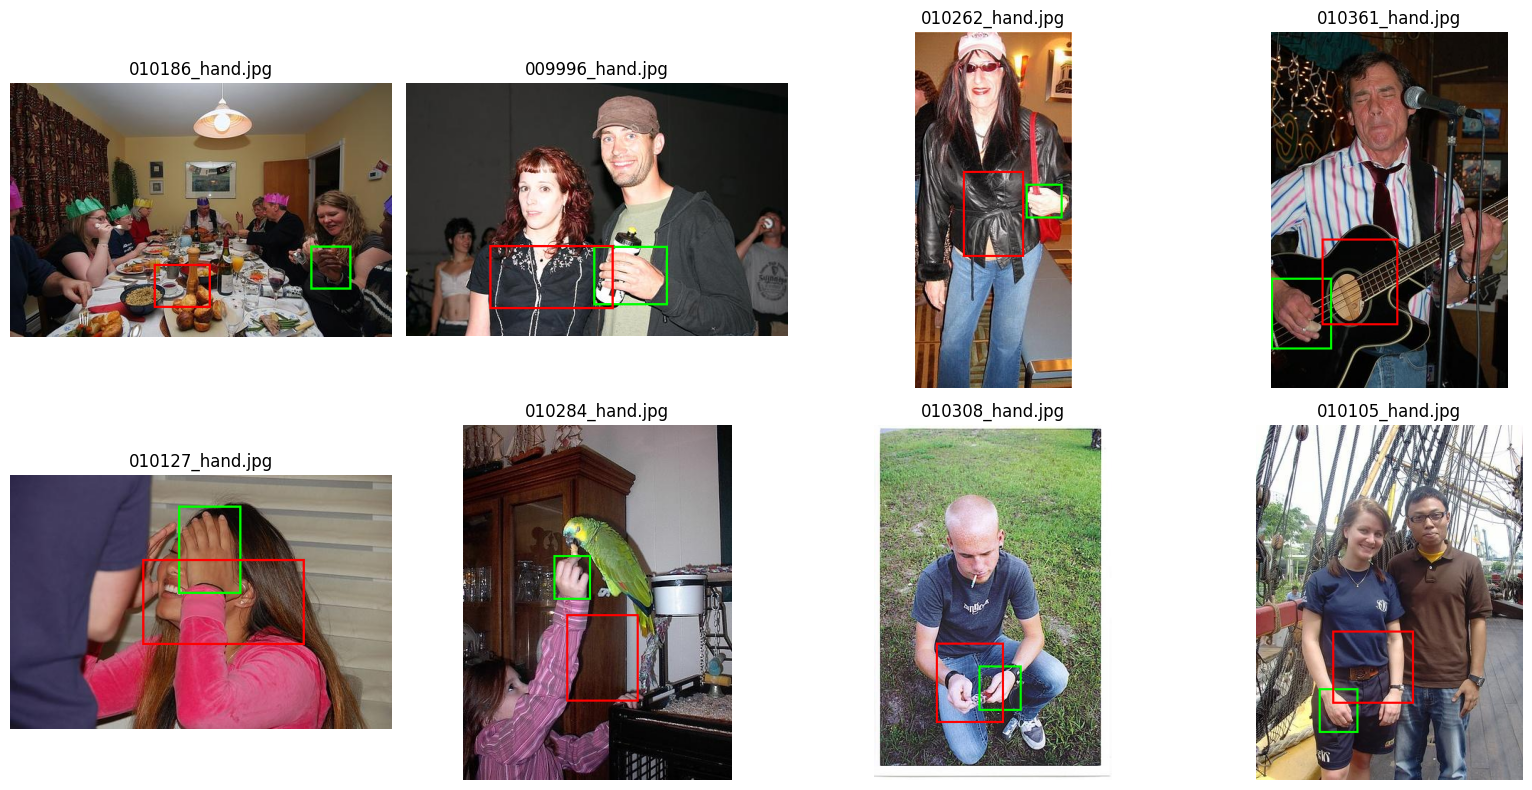

In [ ]:
import pandas as pd, numpy as np, os
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

work = "/content/hand_bbox_baseline/data/work"
val_df = pd.read_csv(f"{work}/val_baseline.csv")

def preprocess_for_model(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img

# sample a few validation images
np.random.seed(7)
vis = val_df.sample(8).reset_index(drop=True)

# Build input batch
batch_imgs = tf.stack([preprocess_for_model(p) for p in vis["image_path"].values], axis=0)
preds = mnv2_cs_ft.predict(batch_imgs, verbose=0)  # [N,4] normalized

# Plot
cols = 4
rows = int(np.ceil(len(vis)/cols))
plt.figure(figsize=(cols*4, rows*4))

for i, row in vis.iterrows():
    img = Image.open(row["image_path"]).convert("RGB")
    W, H = row["width"], row["height"]

    # GT denorm
    gt = (
        row["tx"]*W, row["ty"]*H,
        row["bx"]*W, row["by"]*H
    )

    # Pred denorm
    pr = preds[i]
    pr = np.clip(pr, 0, 1)
    pr = (pr[0]*W, pr[1]*H, pr[2]*W, pr[3]*H)

    draw = ImageDraw.Draw(img)
    # GT = green, Pred = red
    draw.rectangle([(gt[0], gt[1]), (gt[2], gt[3])], outline=(0,255,0), width=3)
    draw.rectangle([(pr[0], pr[1]), (pr[2], pr[3])], outline=(255,0,0), width=3)

    plt.subplot(rows, cols, i+1)
    plt.imshow(img)
    plt.title(os.path.basename(row["image_path"]))
    plt.axis("off")

plt.tight_layout()
plt.show()


# Model FineTunning V2 Yolov8-nano

In [13]:
from pathlib import Path
from glob import glob
import os, shutil, xml.etree.ElementTree as ET

PROJ = Path("/content/hand_bbox_detector")
DATA = PROJ / "data"
YOLO_DATA_DIR = DATA / "yolo"         # where YOLO-format labels/images will live
RAW_VOC = Path("/content/hand_bbox_baseline/data/raw/hand_dataset/evaluation_code/VOC2007/VOCdevkit/VOC2007")  # from your previous section

for p in [PROJ, DATA, YOLO_DATA_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("VOC root:", RAW_VOC)
print("Exists:", RAW_VOC.exists())


!pip -q install ultralytics==8.1.0
!pip install --upgrade ultralytics

# The import of ultralytics.YOLO here was causing the name collision with the Path object.
# By renaming YOLO to YOLO_DATA_DIR, we avoid this conflict.
from ultralytics import YOLO
import torch

VOC root: /content/hand_bbox_baseline/data/raw/hand_dataset/evaluation_code/VOC2007/VOCdevkit/VOC2007
Exists: True
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 699.2/699.2 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.9/44.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 34.4 MB/s eta 0:00:00
  Attempting uninstall: ultralytics
    Found existing installation: ultralytics 8.1.0
    Uninstalling ultralytics-8.1.0:
      Successfully uninstalled ultralytics-8.1.0
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## Convert Pascal-VOC → YOLO labels

In [14]:
import random, math

voc_images = RAW_VOC / "JPEGImages"
voc_anns   = RAW_VOC / "Annotations"
voc_sets   = RAW_VOC / "ImageSets" / "Main"

# Try to read official splits if they exist
def read_split_list(fname):
    f = voc_sets / fname
    if not f.exists(): return None
    ids = [line.strip() for line in open(f) if line.strip()]
    return [f"{i}.jpg" if i.endswith(".jpg")==False else i for i in ids]

train_ids = read_split_list("hand_train_big.txt")
test_ids  = read_split_list("hand_test_big.txt")
val_ids   = read_split_list("hand_val_big.txt")

all_imgs = sorted([os.path.basename(p) for p in glob(str(voc_images/"*.jpg"))])

if train_ids is None:
    # fallback: random split 80/20
    random.seed(42)
    random.shuffle(all_imgs)
    split = int(0.8 * len(all_imgs))
    train_ids = all_imgs[:split]
    val_ids   = all_imgs[split:]
else:
    # If there is only train/test, use test as val
    if val_ids is None:
        val_ids = test_ids if test_ids is not None else []

print("Train:", len(train_ids), " Val:", len(val_ids))

# Create YOLO dirs
for sub in ["images/train","images/val","labels/train","labels/val"]:
    (YOLO_DATA_DIR / sub).mkdir(parents=True, exist_ok=True)

# helper: VOC XML -> YOLO txt
def voc_to_yolo(xmin,ymin,xmax,ymax,W,H):
    cx = (xmin+xmax)/2.0 / W
    cy = (ymin+ymax)/2.0 / H
    w  = (xmax-xmin) / W
    h  = (ymax-ymin) / H
    return max(0,min(1,cx)), max(0,min(1,cy)), max(0,min(1,w)), max(0,min(1,h))

# Convert a set
def convert_split(id_list, split):
    for img_name in id_list:
        img_path = voc_images / img_name
        xml_path = voc_anns / (os.path.splitext(img_name)[0] + ".xml")
        if not img_path.exists() or not xml_path.exists():
            continue

        # copy image
        out_img = YOLO_DATA_DIR / "images" / split / img_name
        if not out_img.exists():
            shutil.copy2(img_path, out_img)

        # parse xml -> label txt
        root = ET.parse(xml_path).getroot()
        W = int(root.find("size/width").text)
        H = int(root.find("size/height").text)

        lines = []
        for obj in root.findall("object"):
            name = obj.findtext("name").strip().lower()
            if name != "hand":  # single class
                continue
            b = obj.find("bndbox")
            xmin = int(float(b.findtext("xmin"))); ymin = int(float(b.findtext("ymin")))
            xmax = int(float(b.findtext("xmax"))); ymax = int(float(b.findtext("ymax")))
            # clamp
            xmin = max(0, min(xmin, W-1)); xmax = max(0, min(xmax, W-1))
            ymin = max(0, min(ymin, H-1)); ymax = max(0, min(ymax, H-1))
            if xmax <= xmin or ymax <= ymin:
                continue
            cx,cy,w,h = voc_to_yolo(xmin,ymin,xmax,ymax,W,H)
            lines.append(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")

        out_lbl = YOLO_DATA_DIR / "labels" / split / (os.path.splitext(img_name)[0] + ".txt")
        with open(out_lbl, "w") as f:
            f.write("\n".join(lines))

convert_split(train_ids, "train")
convert_split(val_ids,   "val")

print("Done. Example label file with first non-empty:")
import itertools
for p in itertools.chain(glob(str((YOLO_DATA_DIR/"labels/train")/"*.txt")),
                         glob(str((YOLO_DATA_DIR/"labels/val")/"*.txt"))):
    if os.path.getsize(p) > 0:
        print(p); print(open(p).read()); break

Train: 348  Val: 88
Done. Example label file with first non-empty:
/content/hand_bbox_detector/data/yolo/labels/train/010044_hand.txt
0 0.529333 0.915000 0.269333 0.166000
0 0.768000 0.890000 0.186667 0.200000


## Create the Yolo data.yml

In [15]:
yaml_text = f"""
path: {YOLO_DATA_DIR}
train: images/train
val: images/val
names:
  0: hand
"""
(DATA / "hand_data.yaml").write_text(yaml_text)
print((DATA / "hand_data.yaml").read_text())


path: /content/hand_bbox_detector/data/yolo
train: images/train
val: images/val
names:
  0: hand



## Train YOLOv8-nano (multi-hand)

#### Normal Yolov8nano

In [ ]:
from ultralytics import YOLO
import torch  # Add this import

# Create a fresh model (nano)
model = YOLO("yolov8n.pt")   # pretrained COCO weights

# Train
results = model.train(
    data=str(DATA/"hand_data.yaml"),
    imgsz=512,
    epochs=50,
    batch=16,
    lr0=0.01,
    device=0 if torch.cuda.is_available() else 'cpu',  # Changed this line
    patience=10,          # early stopping on val metrics
    optimizer="SGD",      # or "AdamW"
    name="yolov8n_hands",
    project=str(PROJ/"runs")
)

Ultralytics 8.3.228 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hand_bbox_detector/data/hand_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolov8n_hands, nbs=64, nms=False, opset=None, optimize=False, optimizer=SGD, overlap_mask=True, patience=10, perspective=0

#### Yolov8nano fine tuned best weights at higher resolution

In [ ]:
from ultralytics import YOLO
model = YOLO("/content/hand_bbox_detector/runs/yolov8n_hands2/weights/best.pt")

results = model.train(
    data=str(DATA/"hand_data.yaml"),
    imgsz=640,           # ↑ from 512
    epochs=30,
    batch=12,            # reduce if you hit OOM; try 16 first
    lr0=0.005,           # slightly lower LR for fine-tune
    device=0,
    patience=10,
    optimizer="SGD",
    name="yolov8n_hands_ft640",
    project=str(PROJ/"runs")
)


Ultralytics 8.3.228 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=12, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hand_bbox_detector/data/hand_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/hand_bbox_detector/runs/yolov8n_hands2/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolov8n_hands_ft640, nbs=64, nms=False, opset=None, optimize=False, 

#### Normal Yolov8small (Bigger Model)

In [16]:
from ultralytics import YOLO
model = YOLO("yolov8s.pt")  # larger than nano

results = model.train(
    data=str(DATA/"hand_data.yaml"),
    imgsz=640,
    epochs=50,
    batch=8,              # s uses more memory
    lr0=0.01,
    device=0,
    patience=12,
    optimizer="SGD",
    name="yolov8s_hands_640",
    project=str(PROJ/"runs")
)


Ultralytics 8.3.229 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hand_bbox_detector/data/hand_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolov8s_hands_640, nbs=64, nms=False, opset=None, optimize=False, optimizer=SGD, overlap_mask=True, patience=12, perspectiv

#### Test mBest model

In [17]:
best = YOLO(str(PROJ/"runs"/"yolov8s_hands_640"/"weights"/"best.pt"))

# Evaluate on val set (reports Precision/Recall/mAP)
metrics = best.val(data=str(DATA/"hand_data.yaml"), imgsz=512)
print("mAP@0.5:", metrics.box.map50, "  mAP@0.5:0.95:", metrics.box.map)

# Visualize a few predictions
pred = best.predict(
    source=str(YOLO_DATA_DIR/"images/val"),
    imgsz=512,
    conf=0.35,   # was default 0.25
    iou=0.45,    # NMS IOU (default 0.7); lower merges less, reduces spurious overlaps
    save=True, max_det=20
)
print("Saved to:", pred[0].save_dir)


Ultralytics 8.3.229 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 506.9±158.1 MB/s, size: 30.3 KB)
val: Scanning /content/hand_bbox_detector/data/yolo/labels/val.cache... 88 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 88/88 25.5Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.1it/s 2.9s
                   all         88        142      0.777      0.746      0.803      0.462
Speed: 3.2ms preprocess, 11.1ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to /content/runs/detect/val
mAP@0.5: 0.8031259866611101   mAP@0.5:0.95: 0.4623761519487612

image 1/88 /content/hand_bbox_detector/data/yolo/images/val/009988_hand.jpg: 512x384 1 hand, 46.6ms
image 2/88 /content/hand_bbox_detector/data/yolo/images/val/009997_hand.jpg: 512x352 1 hand, 42.6ms
i

#### Personal Photo Test

In [18]:
from google.colab import files
uploaded = files.upload()  # pick a local JPG/PNG with your hand visible
img_path = list(uploaded.keys())[0]
img_path

Saving foto1.jpeg to foto1.jpeg


'foto1.jpeg'

In [20]:
from ultralytics import YOLO
best = YOLO(str(PROJ/"runs"/"yolov8s_hands_640"/"weights"/"best.pt"))

In [21]:
res = best.predict(
    source=img_path,
    imgsz=640,     # you can try 512 or 640
    conf=0.35,     # try 0.35–0.5 if you see FPs
    iou=0.45,      # NMS IoU
    save=True
)
res[0]


image 1/1 /content/foto1.jpeg: 640x480 2 hands, 47.6ms
Speed: 2.4ms preprocess, 47.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict2


ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
keypoints: None
masks: None
names: {0: 'hand'}
obb: None
orig_img: array([[[192, 180, 174],
        [192, 180, 174],
        [192, 180, 174],
        ...,
        [182, 168, 156],
        [181, 167, 155],
        [181, 167, 155]],

       [[192, 180, 174],
        [192, 180, 174],
        [192, 180, 174],
        ...,
        [182, 168, 156],
        [181, 167, 155],
        [181, 167, 155]],

       [[192, 180, 174],
        [192, 180, 174],
        [192, 180, 174],
        ...,
        [182, 168, 156],
        [181, 167, 155],
        [181, 167, 155]],

       ...,

       [[209, 220, 224],
        [209, 220, 224],
        [209, 220, 224],
        ...,
        [  1,   1,   1],
        [  1,   1,   1],
        [  1,   1,   1]],

       [[209, 220, 224],
        [209, 220, 224],
        [209, 220, 224],
        ...,
        [  1,   1,   1],
        [  1,   1,   1],
        [  1,  

(np.float64(-0.5), np.float64(1199.5), np.float64(1599.5), np.float64(-0.5))

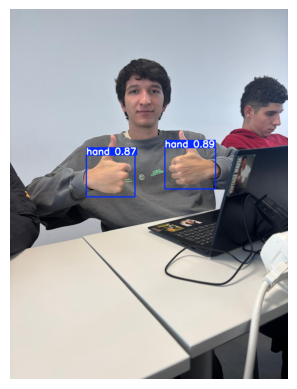

In [22]:
import matplotlib.pyplot as plt
import numpy as np

r = res[0]                     # first (and only) image result
annot = r.plot()               # returns a BGR numpy image with boxes+labels
plt.imshow(annot[..., ::-1])   # convert BGR->RGB for matplotlib
plt.axis("off")
